# 01 · Axe 1 Adoption (Ruben COMBE--TAMAIN)

**Questions :** qui utilise l'IA au travail ? avec quels types d'outils ? à quel rythme ?

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # le notebook vit dans notebooks/ : on importe devia depuis la racine
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160, "display.max_columns", 30)
from devia import data, population
d26 = data.prepare_2026(data.load_2026()); d25 = data.prepare_2025(data.load_2025())
p26, p25 = d26[d26.is_pro_dev], d25[d25.is_pro_dev]          # population par défaut : développeurs professionnels
print(f"2026 : {len(p26):,} développeurs professionnels sur {len(d26):,} répondants | 2025 : {len(p25):,} sur {len(d25):,}")
from devia.axes import adoption

2026 : 20,220 développeurs professionnels sur 30,903 répondants | 2025 : 34,146 sur 49,191


## Qui utilise l'IA ?

In [2]:
print(adoption.overall_adoption(p26))
adoption.adoption_by(p26, "Ancienneté professionnelle").round(3)

{'n': 11803, 'k': 10305, 'share': 0.8730831144624248, 'lo': 0.8669559992907732, 'hi': 0.8789674490258368}


,group,n,k,share,lo,hi
0,0-2 ans,840,705,0.839,0.813,0.863
1,3-5 ans,1509,1331,0.882,0.865,0.897
2,6-10 ans,2471,2169,0.878,0.864,0.890
3,11-20 ans,3865,3418,0.884,0.874,0.894
4,21 ans et +,3022,2608,0.863,0.850,0.875


Pas de gradient net avec l'ancienneté : l'usage est élevé partout, un peu plus bas pour les moins de 3 ans (intervalle à regarder).

In [3]:
adoption.adoption_by(p26, "Métier").round(3)

,group,n,k,share,lo,hi
0,Ingénieur IA / ML,198,189,0.955,0.916,0.976
1,Responsable d'ingénierie,147,137,0.932,0.879,0.963
2,Architecte,903,834,0.924,0.904,0.939
3,Développeur front-end,458,422,0.921,0.893,0.943
4,Développeur mobile,367,330,0.899,0.864,0.926
5,Développeur back-end,2044,1830,0.895,0.881,0.908
6,Data scientist,146,130,0.890,0.829,0.931
7,Développeur full-stack,4185,3681,0.880,0.869,0.889
8,Data engineer,231,203,0.879,0.830,0.915
9,DevOps,244,213,0.873,0.825,0.909


En revanche les métiers diffèrent nettement (ingénieurs IA / ML en haut, développeurs embarqué en bas).

## Quels outils, quel rythme ?

In [4]:
print(adoption.tool_families(p26).round(3)); adoption.frequency_by_family(p26).round(3)

                                     option      n     k  share     lo     hi
0               Assistants / agents de code  11803  8695  0.737  0.729  0.745
1  Assistants conversationnels généralistes  11803  7484  0.634  0.625  0.643
2           Agents ou workflows automatisés  11803  3473  0.294  0.286  0.303
3           Outils internes de l'entreprise  11803  2389  0.202  0.195  0.210


,Tous les jours,Chaque semaine,Mensuel ou moins,n
Assistants / agents de code,0.787,0.172,0.041,8652
Assistants conversationnels généralistes,0.670,0.268,0.062,7453
Agents ou workflows automatisés,0.672,0.236,0.092,3435
Outils internes de l'entreprise,0.490,0.301,0.208,2363


**À retenir :** les assistants / agents de code sont la famille la plus citée, et l'usage est le plus souvent quotidien parmi ceux qui s'en servent.

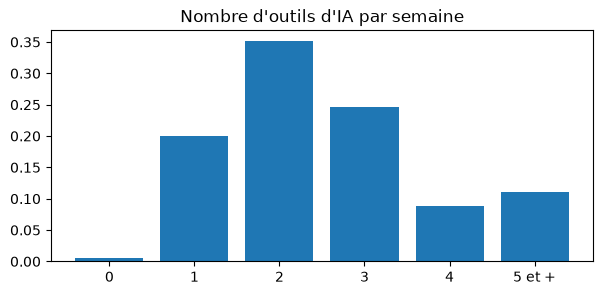

In [5]:
fig, ax = plt.subplots(figsize=(7,3)); t = adoption.tool_count_distribution(p26); ax.bar(t.category, t.share); ax.set_title("Nombre d'outils d'IA par semaine"); plt.show()